# **Dependencies**

In [ ]:
%pip install -q "transformers==4.57.6" "tf-keras"

ERROR: Operation cancelled by user


KeyboardInterrupt: 

In [ ]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import transformers
import tensorflow as tf
from transformers import RobertaTokenizer, TFRobertaModel

print("Transformers:", transformers.__version__)
print("TensorFlow:", tf.__version__)
print("RoBERTa import successful!")
print("GPU:", tf.config.list_physical_devices("GPU"))


Transformers: 4.57.6
TensorFlow: 2.21.0
RoBERTa import successful!
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf

from keras.layers import Dense, Dropout, Embedding, LSTM, Bidirectional
from tensorflow.keras.layers import Embedding, LSTM, Dense, Bidirectional
from tensorflow.keras.layers.experimental.preprocessing import TextVectorization
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from transformers import BertTokenizer, TFBertModel

import numpy as np
import os
import pandas as pd
from sklearn.model_selection import train_test_split

In [ ]:
os.environ["WANDB_API_KEY"] = "0"

In [ ]:
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver()
    tf.config.experimental_connect_to_cluster(tpu)
    tf.tpu.experimental.initialize_tpu_system(tpu)
    strategy = tf.distribute.TPUStrategy(tpu)
except ValueError:
    strategy = tf.distribute.get_strategy() # for CPU and single GPU
    print('Number of replicas:', strategy.num_replicas_in_sync)

Number of replicas: 1


In [ ]:
max_length = 200
batch_size = 32
# dev_size = 0.25

In [ ]:
from transformers import AutoTokenizer, AutoModelForMaskedLM
tokenizer = AutoTokenizer.from_pretrained("roberta-base")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

### **Dataset Preparation**

In [ ]:
from sklearn import preprocessing
le = preprocessing.LabelEncoder()

In [ ]:
df = pd.read_csv('FINCORP.csv')
df = df.sample(frac = 1)

**Label Encoding**

In [ ]:
df['Emotion'] = le.fit_transform(df['Emotion'])
df['Severity level'] = le.fit_transform(df['Severity level'])
df['Sentiment'] = le.fit_transform(df['Sentiment'])
df['Emotion'] = le.fit_transform(df['Emotion'])

In [ ]:
df

,Domain,Complaint/ Opinion,Complaint Label,Severity level,Sentiment,Emotion
5961,Stocks and investment,#SundayRead | Advisors have been asking invest...,0,4,2,4
6242,Financial Policies,@GeorgeGammon I can already see the carbon cre...,0,4,1,6
5667,Stocks and investment,#BestOfTheWeek | Are you planning to invest in...,0,4,1,4
6112,Financial Policies,@mineCityCoins .@chicagosmayor please consider...,0,4,2,3
5356,Debit card,My credit score went up 9 points. Y’all better...,0,4,1,6
...,...,...,...,...,...,...
315,Loan,"@ICICIBank_Care @ICICIBank Dear Sir / Madam, ....",1,1,0,5
2469,Consumer transaction complaints,@fe4175fec332463 @Pepperfry @jagograhakjago mi...,1,1,0,5
763,Customer Service,@ICICIBank_Care It's been over 24 hours since ...,1,1,0,5
5063,Debit card,I desided to take this escort stuff to a diffe...,0,4,2,4


### **Tokenization (RoBERTa)**

In [ ]:
def bert_encode(data):
    tokens = tokenizer.batch_encode_plus(data, max_length=max_length, padding='max_length', truncation=True)

    return tf.constant(tokens['input_ids'])

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df,  test_size=0.3, shuffle=True, random_state=42)

In [ ]:
df_train, df_val = train_test_split(df_train,  test_size=0.15, shuffle=True, random_state=42)

In [ ]:
train_encoded = bert_encode(df_train['Complaint/ Opinion'].values.tolist())

In [ ]:
train_encoded.numpy().shape

(3736, 200)

In [ ]:
test_encoded = bert_encode(df_test['Complaint/ Opinion'].values.tolist())

In [ ]:
test_encoded.numpy().shape

(1885, 200)

In [ ]:
val_encoded = bert_encode(df_val['Complaint/ Opinion'].values.tolist())

### **Creating Batched Dataset**

In [ ]:
# For Single task experiments
def gen_data1(x,y,batch_size=32):

  num_examples = len(y)

  while True:
    x_batch = np.zeros((batch_size, 200))
    y_batch = np.zeros((batch_size, ))

    for i in range(0, batch_size):

      index = np.random.randint(0, num_examples)
      text , emo = x[index], y[index]

      x_batch[i] = text
      y_batch[i] = emo

    yield x_batch, y_batch

# For Bi-task Experiments
def gen_data2(x,y,z, batch_size=32):

  num_examples = len(y)

  while True:
    x_batch = np.zeros((batch_size, 200))
    y_batch = np.zeros((batch_size, ))
    z_batch = np.zeros((batch_size, ))

    for i in range(0, batch_size):

      index = np.random.randint(0, num_examples)
      text, comp, sev= x[index], y[index], z[index]

      x_batch[i] = text
      y_batch[i] = comp
      z_batch[i] = sev

    yield x_batch, [y_batch, z_batch]

# For Tri-task Experiments
def gen_data3(x,y,z, p, batch_size=32):

  num_examples = len(y)

  while True:
    x_batch = np.zeros((batch_size, 200))
    y_batch = np.zeros((batch_size, ))
    z_batch = np.zeros((batch_size, ))
    p_batch = np.zeros((batch_size, ))

    for i in range(0, batch_size):

      index = np.random.randint(0, num_examples)
      text, comp, sev, sent = x[index], y[index], z[index], p[index]

      x_batch[i] = text
      y_batch[i] = comp
      z_batch[i] = sev
      p_batch[i] = sent

    yield x_batch, [y_batch, z_batch, p_batch]

# For MTL experiments, ie all 4 tasks together
def gen_data4(x,y,z, p, q, batch_size=32):

  num_examples = len(y)

  while True:
    x_batch = np.zeros((batch_size, 200))
    y_batch = np.zeros((batch_size, ))
    z_batch = np.zeros((batch_size, ))
    p_batch = np.zeros((batch_size, ))
    q_batch = np.zeros((batch_size, ))

    for i in range(0, batch_size):

      index = np.random.randint(0, num_examples)
      text, comp, sev, sent, emo = x[index], y[index], z[index], p[index], q[index]

      x_batch[i] = text
      y_batch[i] = comp
      z_batch[i] = sev
      p_batch[i] = sent
      q_batch[i] = emo

    yield x_batch, [y_batch, z_batch, p_batch, q_batch]

In [ ]:
# Non-shuffled batches for getting the predictions on testing data and Macro F1 score calculation
def gen_data_mtl(x,y,z, p,q, batch_size= 32):

  xbatched = []
  ybatched = []
  zbatched = []
  pbatched = []
  qbatched = []


  num_examples = len(y)
  num = len(x)//batch_size
  i = 1

  while (i<num):

    xbatched.append(x[32*i:32*(i+1)])
    ybatched.append(y[32*i:32*(i+1)])
    zbatched.append(z[32*i:32*(i+1)])
    pbatched.append(p[32*i:32*(i+1)])
    qbatched.append(q[32*i:32*(i+1)])
    i+=1

  return xbatched, [ybatched, zbatched, pbatched, qbatched]

# Non-shuffled batches
def gen_data_tri(x,y,z, p, batch_size= 32):

  xbatched = []
  ybatched = []
  zbatched = []
  pbatched = []


  num_examples = len(y)
  num = len(x)//batch_size
  i = 1

  while (i<num):

    xbatched.append(x[32*i:32*(i+1)])
    ybatched.append(y[32*i:32*(i+1)])
    zbatched.append(z[32*i:32*(i+1)])
    pbatched.append(p[32*i:32*(i+1)])
    i+=1

  return xbatched, [ybatched, zbatched, pbatched]

In [ ]:
train_er = gen_data4(train_encoded.numpy(),
                     df_train['Complaint Label'].values ,
                     df_train['Severity level'].values,
                     df_train['Sentiment'].values,
                     df_train['Emotion'].values)

In [ ]:
test_er = gen_data4(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
val_er = gen_data4(val_encoded.numpy(),
                   df_val['Complaint Label'].values ,
                   df_val['Severity level'].values,
                   df_val['Sentiment'].values,
                   df_val['Emotion'].values)

# **Model Building**

In [ ]:
from transformers import TFAutoModel

bert_encoder = TFAutoModel.from_pretrained(
    "roberta-base",
    use_safetensors=False)

print("RoBERTa loaded successfully!")

tf_model.h5:   0%|          | 0.00/657M [00:00<?, ?B/s]

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some layers from the model checkpoint at roberta-base were not used when initializing TFRobertaModel: ['lm_head']
- This IS expected if you are initializing TFRobertaModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFRobertaModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
All the layers of TFRobertaModel were initialized from the model checkpoint at roberta-base.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFRobertaModel for predictions without further training.


RoBERTa loaded successfully!


In [ ]:
def bert_tweets_model_quad():

    # Shared Layers - 1. RoBERTa embeddings 2. BiGRU layer
    input_word_ids = tf.keras.Input(shape=(max_length,), dtype=tf.int32, name="input_ids")
    last_hidden_states = bert_encoder(input_word_ids)[0]
    x = Bidirectional(tf.keras.layers.GRU(100, dropout=0.3, recurrent_dropout=0.3))(last_hidden_states)

    # Sentiment detection task (Auxiliary Task)
    output3 = tf.keras.layers.Dense(3, activation='softmax', name='sent')(x)

    # Emotion Detection task (Auxiliary Task)
    output4 = tf.keras.layers.Dense(7, activation='softmax', name='emo')(x)

    # Severity Detection Task with information from Auxiliary tasks fed
    add = tf.keras.layers.Concatenate(axis=1)([x, output3, output4])
    output2 = tf.keras.layers.Dense(5, activation='softmax', name='sev')(add)

    # Complaint Detection Task with information from Auxiliary tasks fed
    add = tf.keras.layers.Concatenate(axis=1)([x, output3 , output4])
    output1 = tf.keras.layers.Dense(1, activation='sigmoid', name='comp')(add)

    model = tf.keras.Model(inputs=input_word_ids, outputs=[output1,output2,output3, output4])

    return model

In [ ]:
model_diag = bert_tweets_model_quad()

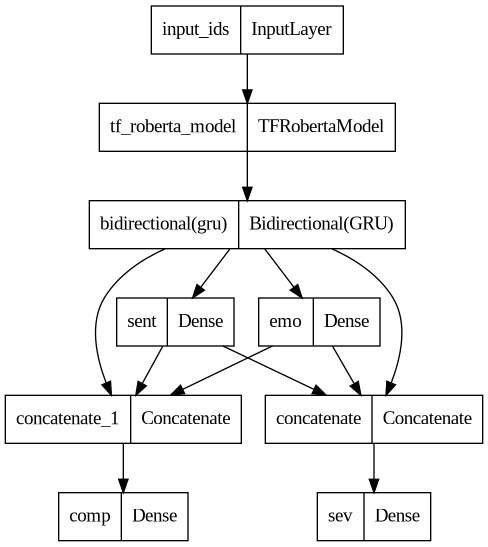

In [ ]:
tf.keras.utils.plot_model(model_diag)

# **Final Execution**

## **Experiment 1**

In [ ]:
model = bert_tweets_model_quad()

adam_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5)

losses = {
"comp": "binary_crossentropy",
"sev": "sparse_categorical_crossentropy",
"sent": "sparse_categorical_crossentropy",
"emo": "sparse_categorical_crossentropy"
}

lossWeights = {"comp": 1.0, "sev": 1.0, "sent":0.5, "emo":0.5}
# run_opts = tf.RunOptions(report_tensor_allocations_upon_oom = True)
model.compile(loss=losses,loss_weights=lossWeights, optimizer=adam_optimizer,metrics=['accuracy'])

# train the model
_ = model.fit(
    train_er,
    validation_data = val_er,
    steps_per_epoch = 150,
    validation_steps = 100,
    epochs = 3,
    verbose = True)

# validate the model


Epoch 1/3


150/150 [==============================] - 493s 3s/step - loss: 2.7613 - comp_loss: 0.4890 - sev_loss: 1.0432 - sent_loss: 0.8797 - emo_loss: 1.5785 - comp_accuracy: 0.7404 - sev_accuracy: 0.5958 - sent_accuracy: 0.6054 - emo_accuracy: 0.4329 - val_loss: 2.2792 - val_comp_loss: 0.3315 - val_sev_loss: 0.8997 - val_sent_loss: 0.7490 - val_emo_loss: 1.3468 - val_comp_accuracy: 0.8487 - val_sev_accuracy: 0.6509 - val_sent_accuracy: 0.6459 - val_emo_accuracy: 0.5241
Epoch 2/3
150/150 [==============================] - 433s 3s/step - loss: 1.8228 - comp_loss: 0.1790 - sev_loss: 0.6785 - sent_loss: 0.6479 - emo_loss: 1.2827 - comp_accuracy: 0.9367 - sev_accuracy: 0.7429 - sent_accuracy: 0.7033 - emo_accuracy: 0.5367 - val_loss: 1.5940 - val_comp_loss: 0.1189 - val_sev_loss: 0.6185 - val_sent_loss: 0.5827 - val_emo_loss: 1.1305 - val_comp_accuracy: 0.9641 - val_sev_accuracy: 0.7594 - val_sent_accuracy: 0.7306 - val_emo_accuracy: 0.5881
Epoch 3/3
150/150 [==============================] - 432s 

In [ ]:
acc = model.evaluate(test_er, steps = 100, verbose = True)

100/100 [==============================] - 58s 579ms/step - loss: 1.5089 - comp_loss: 0.1171 - sev_loss: 0.5417 - sent_loss: 0.5773 - emo_loss: 1.1231 - comp_accuracy: 0.9641 - sev_accuracy: 0.8034 - sent_accuracy: 0.7544 - emo_accuracy: 0.5678


In [ ]:
test_pred_data,[y_pred,z_pred, p_pred,q_pred] = gen_data_mtl(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
test_pred_data

[array([[    0, 12350,   819, ...,     1,     1,     1],
        [    0,  6209,    42, ...,     1,     1,     1],
        [    0,  1039, 35166, ...,     1,     1,     1],
        ...,
        [    0,  1039,   487, ...,     1,     1,     1],
        [    0,  1039, 36283, ...,     1,     1,     1],
        [    0,  1116,   768, ...,     1,     1,     1]],
       shape=(32, 200), dtype=int32),
 array([[    0,  1039,  2371, ...,     1,     1,     1],
        [    0,  1039, 36118, ...,     1,     1,     1],
        [    0, 13368,   787, ...,     1,     1,     1],
        ...,
        [    0,  1039,  2371, ...,     1,     1,     1],
        [    0,  1039, 22886, ...,     1,     1,     1],
        [    0, 37562,    73, ...,     1,     1,     1]],
       shape=(32, 200), dtype=int32),
 array([[    0,  1039,  3376, ...,     1,     1,     1],
        [    0,  1039, 44623, ...,     1,     1,     1],
        [    0,  1039, 14507, ...,     1,     1,     1],
        ...,
        [    0,  1039,   487

In [ ]:
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score

def macrof1s(y_true, y_pred):
  return f1_score(y_true, y_pred, average='macro')

acc1 = []
mfs1 = []
acc2 = []
mfs2 = []
acc3 = []
mfs3 = []
acc4 = []
mfs4 = []

for idx in range(len(test_pred_data)):
  yp1, zp1, pp1, qp1 = model.predict(test_pred_data[idx])

  yp2 = []
  for i in yp1:
    if(i>0.5):
      yp2.append(1)
    else:
      yp2.append(0)

  zp2 = zp1.argmax(axis = -1)
  pp2 = pp1.argmax(axis = -1)
  qp2 = qp1.argmax(axis = -1)

  acc1.append(accuracy_score(yp2, y_pred[idx]))
  acc2.append(accuracy_score(zp2, z_pred[idx]))
  acc3.append(accuracy_score(pp2, p_pred[idx]))
  acc4.append(accuracy_score(qp2, q_pred[idx]))


  mfs1.append(f1_score(yp2, y_pred[idx], average='macro'))
  mfs2.append(f1_score(zp2, z_pred[idx], average='macro'))
  mfs3.append(f1_score(pp2, p_pred[idx], average='macro'))
  mfs4.append(f1_score(qp2, q_pred[idx], average='macro'))


1/1 [==============================] - 1s 646ms/step


**Final Macro F1 Score and Testing Accuracy**

In [ ]:
#Complaint Detection Task -
print("Accuracy : ", sum(acc1)/len(acc1))
print("Macro F1 Score : ", sum(mfs1)/len(mfs1))

Accuracy :  0.9594298245614035
Macro F1 Score :  0.9578456167494115


In [ ]:
#Severity Detection Task -
print("Accuracy : ", sum(acc2)/len(acc2))
print("Macro F1 Score : ", sum(mfs2)/len(mfs2))

Accuracy :  0.8048245614035088
Macro F1 Score :  0.6259474390892215


In [ ]:
#Sentiment Detection Task -
print("Accuracy : ", sum(acc3)/len(acc3))
print("Macro F1 Score : ", sum(mfs3)/len(mfs3))

Accuracy :  0.7576754385964912
Macro F1 Score :  0.6531430621367407


In [ ]:
#Emotion Detection Task -
print("Accuracy : ", sum(acc4)/len(acc4))
print("Macro F1 Score : ", sum(mfs4)/len(mfs4))

Accuracy :  0.5740131578947368
Macro F1 Score :  0.3252324209864252


## **Experiment 2**

In [ ]:
model = bert_tweets_model_quad()

adam_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5)

losses = {
"comp": "binary_crossentropy",
"sev": "sparse_categorical_crossentropy",
"sent": "sparse_categorical_crossentropy",
"emo": "sparse_categorical_crossentropy"
}

lossWeights = {"comp": 1.0, "sev": 1.0, "sent":0.5, "emo":0.5}
# run_opts = tf.RunOptions(report_tensor_allocations_upon_oom = True)
model.compile(loss=losses,loss_weights=lossWeights, optimizer=adam_optimizer,metrics=['accuracy'])

# train the model
_ = model.fit(
    train_er,
    validation_data = val_er,
    steps_per_epoch = 150,
    validation_steps = 100,
    epochs = 3,
    verbose = True
    )

# validate the model


Epoch 1/3


150/150 [==============================] - 488s 3s/step - loss: 1.1827 - comp_loss: 0.0619 - sev_loss: 0.3651 - sent_loss: 0.4663 - emo_loss: 1.0452 - comp_accuracy: 0.9873 - sev_accuracy: 0.8767 - sent_accuracy: 0.8108 - emo_accuracy: 0.6329 - val_loss: 1.2237 - val_comp_loss: 0.0552 - val_sev_loss: 0.4454 - val_sent_loss: 0.4527 - val_emo_loss: 0.9936 - val_comp_accuracy: 0.9869 - val_sev_accuracy: 0.8481 - val_sent_accuracy: 0.8253 - val_emo_accuracy: 0.6534
Epoch 2/3
150/150 [==============================] - 434s 3s/step - loss: 0.8710 - comp_loss: 0.0231 - sev_loss: 0.2453 - sent_loss: 0.3523 - emo_loss: 0.8529 - comp_accuracy: 0.9962 - sev_accuracy: 0.9142 - sent_accuracy: 0.8656 - emo_accuracy: 0.6979 - val_loss: 1.4000 - val_comp_loss: 0.0761 - val_sev_loss: 0.5038 - val_sent_loss: 0.5928 - val_emo_loss: 1.0475 - val_comp_accuracy: 0.9778 - val_sev_accuracy: 0.8303 - val_sent_accuracy: 0.8025 - val_emo_accuracy: 0.6391
Epoch 3/3
 45/150 [========>.....................] - ETA: 

In [ ]:
acc = model.evaluate(test_er, steps = 100, verbose = True)

100/100 [==============================] - 62s 617ms/step - loss: 1.4049 - comp_loss: 0.0961 - sev_loss: 0.4930 - sent_loss: 0.5562 - emo_loss: 1.0756 - comp_accuracy: 0.9725 - sev_accuracy: 0.8222 - sent_accuracy: 0.7663 - emo_accuracy: 0.6169


In [ ]:
test_pred_data,[y_pred,z_pred, p_pred,q_pred] = gen_data_mtl(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
test_pred_data

[array([[    0, 13082,   640, ...,     1,     1,     1],
        [    0,  1039,   625, ...,     1,     1,     1],
        [    0,  1039, 13368, ...,     1,     1,     1],
        ...,
        [    0,   133,   788, ...,     1,     1,     1],
        [    0,   104,   947, ...,     1,     1,     1],
        [    0,  5975,  2156, ...,     1,     1,     1]],
       shape=(32, 200), dtype=int32),
 array([[    0,  1039,   571, ...,     1,     1,     1],
        [    0,  1039,   250, ...,     1,     1,     1],
        [    0, 43073, 15585, ...,     1,     1,     1],
        ...,
        [    0,  9335,    38, ...,     1,     1,     1],
        [    0,  1039,  2371, ...,     1,     1,     1],
        [    0, 47676,  8179, ...,     1,     1,     1]],
       shape=(32, 200), dtype=int32),
 array([[    0, 43354,   201, ...,     1,     1,     1],
        [    0,   133,   849, ...,     1,     1,     1],
        [    0,  1039,  9325, ...,     1,     1,     1],
        ...,
        [    0,  1039,   500

In [ ]:
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score

def macrof1s(y_true, y_pred):
  return f1_score(y_true, y_pred, average='macro')

acc1 = []
mfs1 = []
acc2 = []
mfs2 = []
acc3 = []
mfs3 = []
acc4 = []
mfs4 = []

for idx in range(len(test_pred_data)):
  yp1, zp1, pp1, qp1 = model.predict(test_pred_data[idx])

  yp2 = []
  for i in yp1:
    if(i>0.5):
      yp2.append(1)
    else:
      yp2.append(0)

  zp2 = zp1.argmax(axis = -1)
  pp2 = pp1.argmax(axis = -1)
  qp2 = qp1.argmax(axis = -1)

  acc1.append(accuracy_score(yp2, y_pred[idx]))
  acc2.append(accuracy_score(zp2, z_pred[idx]))
  acc3.append(accuracy_score(pp2, p_pred[idx]))
  acc4.append(accuracy_score(qp2, q_pred[idx]))


  mfs1.append(f1_score(yp2, y_pred[idx], average='macro'))
  mfs2.append(f1_score(zp2, z_pred[idx], average='macro'))
  mfs3.append(f1_score(pp2, p_pred[idx], average='macro'))
  mfs4.append(f1_score(qp2, q_pred[idx], average='macro'))


1/1 [==============================] - 1s 612ms/step


### **Final Macro F1 Score and Testing Accuracy**

In [ ]:
#Complaint Detection Task -
print("Accuracy : ", sum(acc1)/len(acc1))
print("Macro F1 Score : ", sum(mfs1)/len(mfs1))

Accuracy :  0.9709429824561403
Macro F1 Score :  0.9701404522228309


In [ ]:
#Severity Detection Task -
print("Accuracy : ", sum(acc2)/len(acc2))
print("Macro F1 Score : ", sum(mfs2)/len(mfs2))

Accuracy :  0.8141447368421053
Macro F1 Score :  0.655476330369209


In [ ]:
#Sentiment Detection Task -
print("Accuracy : ", sum(acc3)/len(acc3))
print("Macro F1 Score : ", sum(mfs3)/len(mfs3))

Accuracy :  0.7730263157894737
Macro F1 Score :  0.670257215429475


In [ ]:
#Emotion Detection Task -
print("Accuracy : ", sum(acc4)/len(acc4))
print("Macro F1 Score : ", sum(mfs4)/len(mfs4))

Accuracy :  0.6151315789473685
Macro F1 Score :  0.4019074326510144


## **Experiment 3**

In [ ]:
df = pd.read_csv('FINCORP.csv')
df = df.sample(frac = 1)

**Label Encoding**

In [ ]:
df['Emotion'] = le.fit_transform(df['Emotion'])
df['Severity level'] = le.fit_transform(df['Severity level'])
df['Sentiment'] = le.fit_transform(df['Sentiment'])
df['Emotion'] = le.fit_transform(df['Emotion'])

In [ ]:
df

,Domain,Complaint/ Opinion,Complaint Label,Severity level,Sentiment,Emotion
3978,Crypto,what a massive failure is twitter. you made i...,0,4,0,5
1134,Customer Service,@AmazonHelp Thank You but please response as s...,1,1,0,5
546,Debit Card,@ICICIBank_Care pls help to downgrade my debit...,1,3,1,5
4620,Stock,@ZeeBusiness @AnilSinghvi_ @sanjiv_bhasin @iif...,0,4,1,4
151,Transaction Fail,@MobiKwikSWAT Wat you have said is @HDFCBank_C...,1,1,0,5
...,...,...,...,...,...,...
4766,Transaction,@Venmo That's cool wish some one would pay my ...,0,4,2,4
1454,Credit card,@HDFCBank_Cares Hello - Today is 4th and I hav...,1,3,0,5
5356,Debit card,My credit score went up 9 points. Y’all better...,0,4,1,6
768,Customer Service,@ICICIBank_Care @ICICIBank @amazonpay\n\nNo re...,1,3,0,5


### **Tokenization (RoBERTa)**

In [ ]:
def bert_encode(data):
    tokens = tokenizer.batch_encode_plus(data, max_length=max_length, padding='max_length', truncation=True)

    return tf.constant(tokens['input_ids'])

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df,  test_size=0.3, shuffle=True, random_state=42)

In [ ]:
df_train, df_val = train_test_split(df_train,  test_size=0.15, shuffle=True, random_state=42)

In [ ]:
train_encoded = bert_encode(df_train['Complaint/ Opinion'].values.tolist())

In [ ]:
train_encoded.numpy().shape

(3736, 200)

In [ ]:
test_encoded = bert_encode(df_test['Complaint/ Opinion'].values.tolist())

In [ ]:
test_encoded.numpy().shape

(1885, 200)

In [ ]:
val_encoded = bert_encode(df_val['Complaint/ Opinion'].values.tolist())

In [ ]:
train_er = gen_data4(train_encoded.numpy(),
                     df_train['Complaint Label'].values ,
                     df_train['Severity level'].values,
                     df_train['Sentiment'].values,
                     df_train['Emotion'].values)

In [ ]:
test_er = gen_data4(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
val_er = gen_data4(val_encoded.numpy(),
                   df_val['Complaint Label'].values ,
                   df_val['Severity level'].values,
                   df_val['Sentiment'].values,
                   df_val['Emotion'].values)

In [ ]:
test_pred_data,[y_pred,z_pred, p_pred,q_pred] = gen_data_mtl(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
model = bert_tweets_model_quad()

adam_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5)

losses = {
"comp": "binary_crossentropy",
"sev": "sparse_categorical_crossentropy",
"sent": "sparse_categorical_crossentropy",
"emo": "sparse_categorical_crossentropy"
}

lossWeights = {"comp": 1.0, "sev": 1.0, "sent":0.5, "emo":0.5}
# run_opts = tf.RunOptions(report_tensor_allocations_upon_oom = True)
model.compile(loss=losses,loss_weights=lossWeights, optimizer=adam_optimizer,metrics=['accuracy'])

# train the model
_ = model.fit(
    train_er,
    validation_data = val_er,
    steps_per_epoch = 150,
    validation_steps = 100,
    epochs = 3,
    verbose = True
    )

# validate the model


Epoch 1/3


150/150 [==============================] - 535s 3s/step - loss: 1.4946 - comp_loss: 0.0971 - sev_loss: 0.5010 - sent_loss: 0.5691 - emo_loss: 1.2238 - comp_accuracy: 0.9681 - sev_accuracy: 0.8121 - sent_accuracy: 0.7479 - emo_accuracy: 0.5619 - val_loss: 1.2625 - val_comp_loss: 0.0626 - val_sev_loss: 0.4172 - val_sent_loss: 0.5338 - val_emo_loss: 1.0317 - val_comp_accuracy: 0.9762 - val_sev_accuracy: 0.8344 - val_sent_accuracy: 0.7912 - val_emo_accuracy: 0.6028
Epoch 2/3
150/150 [==============================] - 469s 3s/step - loss: 1.1553 - comp_loss: 0.0506 - sev_loss: 0.3880 - sent_loss: 0.4488 - emo_loss: 0.9846 - comp_accuracy: 0.9856 - sev_accuracy: 0.8629 - sent_accuracy: 0.8177 - emo_accuracy: 0.6290 - val_loss: 1.1499 - val_comp_loss: 0.0331 - val_sev_loss: 0.3655 - val_sent_loss: 0.5253 - val_emo_loss: 0.9774 - val_comp_accuracy: 0.9919 - val_sev_accuracy: 0.8666 - val_sent_accuracy: 0.7875 - val_emo_accuracy: 0.6428
Epoch 3/3
150/150 [==============================] - 475s 

In [ ]:
acc = model.evaluate(test_er, steps = 100, verbose = True)

100/100 [==============================] - 76s 762ms/step - loss: 1.3119 - comp_loss: 0.0650 - sev_loss: 0.4428 - sent_loss: 0.5321 - emo_loss: 1.0761 - comp_accuracy: 0.9834 - sev_accuracy: 0.8319 - sent_accuracy: 0.7916 - emo_accuracy: 0.6134


In [ ]:
test_pred_data,[y_pred,z_pred, p_pred,q_pred] = gen_data_mtl(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score

def macrof1s(y_true, y_pred):
  return f1_score(y_true, y_pred, average='macro')

acc1 = []
mfs1 = []
acc2 = []
mfs2 = []
acc3 = []
mfs3 = []
acc4 = []
mfs4 = []

for idx in range(len(test_pred_data)):
  yp1, zp1, pp1, qp1 = model.predict(test_pred_data[idx])

  yp2 = []
  for i in yp1:
    if(i>0.5):
      yp2.append(1)
    else:
      yp2.append(0)

  zp2 = zp1.argmax(axis = -1)
  pp2 = pp1.argmax(axis = -1)
  qp2 = qp1.argmax(axis = -1)

  acc1.append(accuracy_score(yp2, y_pred[idx]))
  acc2.append(accuracy_score(zp2, z_pred[idx]))
  acc3.append(accuracy_score(pp2, p_pred[idx]))
  acc4.append(accuracy_score(qp2, q_pred[idx]))


  mfs1.append(f1_score(yp2, y_pred[idx], average='macro'))
  mfs2.append(f1_score(zp2, z_pred[idx], average='macro'))
  mfs3.append(f1_score(pp2, p_pred[idx], average='macro'))
  mfs4.append(f1_score(qp2, q_pred[idx], average='macro'))


1/1 [==============================] - 1s 623ms/step


### **Final Macro F1 Score and Testing Accuracy**

In [ ]:
#Complaint Detection Task -
print("Accuracy : ", sum(acc1)/len(acc1))
print("Macro F1 Score : ", sum(mfs1)/len(mfs1))

Accuracy :  0.9830043859649122
Macro F1 Score :  0.9819285101282095


In [ ]:
#Severity Detection Task -
print("Accuracy : ", sum(acc2)/len(acc2))
print("Macro F1 Score : ", sum(mfs2)/len(mfs2))

Accuracy :  0.837171052631579
Macro F1 Score :  0.6845913926204719


In [ ]:
#Sentiment Detection Task -
print("Accuracy : ", sum(acc3)/len(acc3))
print("Macro F1 Score : ", sum(mfs3)/len(mfs3))

Accuracy :  0.7861842105263158
Macro F1 Score :  0.7141629588770101


In [ ]:
#Emotion Detection Task -
print("Accuracy : ", sum(acc4)/len(acc4))
print("Macro F1 Score : ", sum(mfs4)/len(mfs4))

Accuracy :  0.6134868421052632
Macro F1 Score :  0.4071795919492664


## **Experiment 4**

In [ ]:
model = bert_tweets_model_quad()

adam_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5)

losses = {
"comp": "binary_crossentropy",
"sev": "sparse_categorical_crossentropy",
"sent": "sparse_categorical_crossentropy",
"emo": "sparse_categorical_crossentropy"
}

lossWeights = {"comp": 1.0, "sev": 1.0, "sent":0.5, "emo":0.5}
# run_opts = tf.RunOptions(report_tensor_allocations_upon_oom = True)
model.compile(loss=losses,loss_weights=lossWeights, optimizer=adam_optimizer,metrics=['accuracy'])

# train the model
_ = model.fit(
    train_er,
    validation_data = val_er,
    steps_per_epoch = 150,
    validation_steps = 100,
    epochs = 3,
    verbose = True
    )

# validate the model


Epoch 1/3


150/150 [==============================] - 491s 3s/step - loss: 1.6405 - comp_loss: 0.1372 - sev_loss: 0.5819 - sent_loss: 0.6129 - emo_loss: 1.2299 - comp_accuracy: 0.9517 - sev_accuracy: 0.7846 - sent_accuracy: 0.7298 - emo_accuracy: 0.5554 - val_loss: 1.2828 - val_comp_loss: 0.0754 - val_sev_loss: 0.4073 - val_sent_loss: 0.5400 - val_emo_loss: 1.0602 - val_comp_accuracy: 0.9703 - val_sev_accuracy: 0.8534 - val_sent_accuracy: 0.7825 - val_emo_accuracy: 0.5987
Epoch 2/3
150/150 [==============================] - 432s 3s/step - loss: 1.2963 - comp_loss: 0.0721 - sev_loss: 0.4357 - sent_loss: 0.5075 - emo_loss: 1.0696 - comp_accuracy: 0.9787 - sev_accuracy: 0.8350 - sent_accuracy: 0.7821 - emo_accuracy: 0.5996 - val_loss: 1.2320 - val_comp_loss: 0.0487 - val_sev_loss: 0.3977 - val_sent_loss: 0.5331 - val_emo_loss: 1.0380 - val_comp_accuracy: 0.9822 - val_sev_accuracy: 0.8438 - val_sent_accuracy: 0.7869 - val_emo_accuracy: 0.6094
Epoch 3/3
150/150 [==============================] - 433s 

In [ ]:
acc = model.evaluate(test_er, steps = 100, verbose = True)

100/100 [==============================] - 58s 584ms/step - loss: 1.3914 - comp_loss: 0.1066 - sev_loss: 0.4940 - sent_loss: 0.5264 - emo_loss: 1.0551 - comp_accuracy: 0.9697 - sev_accuracy: 0.8413 - sent_accuracy: 0.7781 - emo_accuracy: 0.6084


In [ ]:
test_pred_data,[y_pred,z_pred, p_pred,q_pred] = gen_data_mtl(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
test_pred_data

[array([[    0,  1039,  2160, ...,     1,     1,     1],
        [    0,   113, 42697, ...,     1,     1,     1],
        [    0,  1039, 31230, ...,     1,     1,     1],
        ...,
        [    0,  1039, 25146, ...,     1,     1,     1],
        [    0,  1039,   387, ...,     1,     1,     1],
        [    0,  1039, 43425, ...,     1,     1,     1]],
       shape=(32, 200), dtype=int32),
 array([[    0,  2895,   352, ...,     1,     1,     1],
        [    0,  1039, 13022, ...,     1,     1,     1],
        [    0, 18938, 34206, ...,     1,     1,     1],
        ...,
        [    0,  1039,  1906, ...,     1,     1,     1],
        [    0,  1039, 47814, ...,     1,     1,     1],
        [    0,  1121,  8835, ...,     1,     1,     1]],
       shape=(32, 200), dtype=int32),
 array([[    0,  1039,   250, ...,     1,     1,     1],
        [    0,   894,    18, ...,     1,     1,     1],
        [    0,  1039,  2371, ...,     1,     1,     1],
        ...,
        [    0,  1039, 25656

In [ ]:
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score

def macrof1s(y_true, y_pred):
  return f1_score(y_true, y_pred, average='macro')

acc1 = []
mfs1 = []
acc2 = []
mfs2 = []
acc3 = []
mfs3 = []
acc4 = []
mfs4 = []

for idx in range(len(test_pred_data)):
  yp1, zp1, pp1, qp1 = model.predict(test_pred_data[idx])

  yp2 = []
  for i in yp1:
    if(i>0.5):
      yp2.append(1)
    else:
      yp2.append(0)

  zp2 = zp1.argmax(axis = -1)
  pp2 = pp1.argmax(axis = -1)
  qp2 = qp1.argmax(axis = -1)

  acc1.append(accuracy_score(yp2, y_pred[idx]))
  acc2.append(accuracy_score(zp2, z_pred[idx]))
  acc3.append(accuracy_score(pp2, p_pred[idx]))
  acc4.append(accuracy_score(qp2, q_pred[idx]))


  mfs1.append(f1_score(yp2, y_pred[idx], average='macro'))
  mfs2.append(f1_score(zp2, z_pred[idx], average='macro'))
  mfs3.append(f1_score(pp2, p_pred[idx], average='macro'))
  mfs4.append(f1_score(qp2, q_pred[idx], average='macro'))


1/1 [==============================] - 1s 541ms/step


### **Final Macro F1 Score and Testing Accuracy**

In [ ]:
#Complaint Detection Task -
print("Accuracy : ", sum(acc1)/len(acc1))
print("Macro F1 Score : ", sum(mfs1)/len(mfs1))

Accuracy :  0.9714912280701754
Macro F1 Score :  0.9708498371456102


In [ ]:
#Severity Detection Task -
print("Accuracy : ", sum(acc2)/len(acc2))
print("Macro F1 Score : ", sum(mfs2)/len(mfs2))

Accuracy :  0.8421052631578947
Macro F1 Score :  0.6623189182640723


In [ ]:
#Sentiment Detection Task -
print("Accuracy : ", sum(acc3)/len(acc3))
print("Macro F1 Score : ", sum(mfs3)/len(mfs3))

Accuracy :  0.7889254385964912
Macro F1 Score :  0.7100178043545915


In [ ]:
#Emotion Detection Task -
print("Accuracy : ", sum(acc4)/len(acc4))
print("Macro F1 Score : ", sum(mfs4)/len(mfs4))

Accuracy :  0.6025219298245614
Macro F1 Score :  0.37383482067199486


## **Experiment 5**

In [ ]:
df = pd.read_csv('FINCORP.csv')
df = df.sample(frac = 1)

**Label Encoding**

In [ ]:
df['Emotion'] = le.fit_transform(df['Emotion'])
df['Severity level'] = le.fit_transform(df['Severity level'])
df['Sentiment'] = le.fit_transform(df['Sentiment'])
df['Emotion'] = le.fit_transform(df['Emotion'])

In [ ]:
df

,Domain,Complaint/ Opinion,Complaint Label,Severity level,Sentiment,Emotion
781,Customer Service,@ICICIBank @ICICIBank_Care sorry to say but ti...,1,2,0,5
6207,Financial Policies,@SkyNews Hitler’s Nazi Philosophy ‘a burden to...,0,4,1,2
1989,Transaction Failure,@ThorNodes Been trying to create more Thor tod...,1,3,0,5
3536,Credit Card,If you don’t have ANY credit:\n\nStart with ge...,0,4,2,3
2654,Consumer transaction complaints,@fabuliv @jagograhakjago She agreed to return ...,1,1,0,5
...,...,...,...,...,...,...
5300,Debit card,@CryptoMeg88 @crypto_iso What’s the best way t...,0,4,1,6
1439,Credit card,Those who have nearby due date for credit card...,1,3,0,5
2054,Transaction Failure,@PandaCapital_io @yousuf_sultana @MetaMate_NFT...,1,3,1,4
6204,Financial Policies,@RogerMarshallMD @SenateGOP Senator Marshall: ...,0,4,1,4


### **Tokenization (RoBERTa)**

In [ ]:
def bert_encode(data):
    tokens = tokenizer.batch_encode_plus(data, max_length=max_length, padding='max_length', truncation=True)

    return tf.constant(tokens['input_ids'])

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df,  test_size=0.3, shuffle=True, random_state=42)

In [ ]:
df_train, df_val = train_test_split(df_train,  test_size=0.15, shuffle=True, random_state=42)

In [ ]:
train_encoded = bert_encode(df_train['Complaint/ Opinion'].values.tolist())

In [ ]:
train_encoded.numpy().shape

(3736, 200)

In [ ]:
test_encoded = bert_encode(df_test['Complaint/ Opinion'].values.tolist())

In [ ]:
test_encoded.numpy().shape

(1885, 200)

In [ ]:
val_encoded = bert_encode(df_val['Complaint/ Opinion'].values.tolist())

In [ ]:
train_er = gen_data4(train_encoded.numpy(),
                     df_train['Complaint Label'].values ,
                     df_train['Severity level'].values,
                     df_train['Sentiment'].values,
                     df_train['Emotion'].values)

In [ ]:
test_er = gen_data4(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
val_er = gen_data4(val_encoded.numpy(),
                   df_val['Complaint Label'].values ,
                   df_val['Severity level'].values,
                   df_val['Sentiment'].values,
                   df_val['Emotion'].values)

In [ ]:
test_pred_data,[y_pred,z_pred, p_pred,q_pred] = gen_data_mtl(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
model = bert_tweets_model_quad()

adam_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5)

losses = {
"comp": "binary_crossentropy",
"sev": "sparse_categorical_crossentropy",
"sent": "sparse_categorical_crossentropy",
"emo": "sparse_categorical_crossentropy"
}

lossWeights = {"comp": 1.0, "sev": 1.0, "sent":0.5, "emo":0.5}
# run_opts = tf.RunOptions(report_tensor_allocations_upon_oom = True)
model.compile(loss=losses,loss_weights=lossWeights, optimizer=adam_optimizer,metrics=['accuracy'])

# train the model
_ = model.fit(
    train_er,
    validation_data = val_er,
    steps_per_epoch = 150,
    validation_steps = 100,
    epochs = 3,
    verbose = True
    )

# validate the model


Epoch 1/3


150/150 [==============================] - 492s 3s/step - loss: 1.3662 - comp_loss: 0.0920 - sev_loss: 0.4337 - sent_loss: 0.5436 - emo_loss: 1.1374 - comp_accuracy: 0.9731 - sev_accuracy: 0.8504 - sent_accuracy: 0.7681 - emo_accuracy: 0.5919 - val_loss: 1.2379 - val_comp_loss: 0.0529 - val_sev_loss: 0.4209 - val_sent_loss: 0.5180 - val_emo_loss: 1.0102 - val_comp_accuracy: 0.9866 - val_sev_accuracy: 0.8603 - val_sent_accuracy: 0.7962 - val_emo_accuracy: 0.6309
Epoch 2/3
150/150 [==============================] - 431s 3s/step - loss: 1.0743 - comp_loss: 0.0341 - sev_loss: 0.3333 - sent_loss: 0.4451 - emo_loss: 0.9689 - comp_accuracy: 0.9915 - sev_accuracy: 0.8783 - sent_accuracy: 0.8223 - emo_accuracy: 0.6496 - val_loss: 1.2056 - val_comp_loss: 0.0503 - val_sev_loss: 0.4245 - val_sent_loss: 0.4684 - val_emo_loss: 0.9931 - val_comp_accuracy: 0.9866 - val_sev_accuracy: 0.8428 - val_sent_accuracy: 0.8178 - val_emo_accuracy: 0.6203
Epoch 3/3
150/150 [==============================] - 434s 

In [ ]:
acc = model.evaluate(test_er, steps = 100, verbose = True)

100/100 [==============================] - 59s 586ms/step - loss: 1.2780 - comp_loss: 0.0698 - sev_loss: 0.4281 - sent_loss: 0.5174 - emo_loss: 1.0430 - comp_accuracy: 0.9844 - sev_accuracy: 0.8612 - sent_accuracy: 0.8125 - emo_accuracy: 0.6266


In [ ]:
test_pred_data,[y_pred,z_pred, p_pred,q_pred] = gen_data_mtl(test_encoded.numpy(),
                    df_test['Complaint Label'].values ,
                    df_test['Severity level'].values ,
                    df_test['Sentiment'].values,
                    df_test['Emotion'].values)

In [ ]:
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score

def macrof1s(y_true, y_pred):
  return f1_score(y_true, y_pred, average='macro')

acc1 = []
mfs1 = []
acc2 = []
mfs2 = []
acc3 = []
mfs3 = []
acc4 = []
mfs4 = []

for idx in range(len(test_pred_data)):
  yp1, zp1, pp1, qp1 = model.predict(test_pred_data[idx])

  yp2 = []
  for i in yp1:
    if(i>0.5):
      yp2.append(1)
    else:
      yp2.append(0)

  zp2 = zp1.argmax(axis = -1)
  pp2 = pp1.argmax(axis = -1)
  qp2 = qp1.argmax(axis = -1)

  acc1.append(accuracy_score(yp2, y_pred[idx]))
  acc2.append(accuracy_score(zp2, z_pred[idx]))
  acc3.append(accuracy_score(pp2, p_pred[idx]))
  acc4.append(accuracy_score(qp2, q_pred[idx]))


  mfs1.append(f1_score(yp2, y_pred[idx], average='macro'))
  mfs2.append(f1_score(zp2, z_pred[idx], average='macro'))
  mfs3.append(f1_score(pp2, p_pred[idx], average='macro'))
  mfs4.append(f1_score(qp2, q_pred[idx], average='macro'))


1/1 [==============================] - 1s 596ms/step


### **Final Macro F1 Score and Testing Accuracy**

In [ ]:
#Complaint Detection Task -
print("Accuracy : ", sum(acc1)/len(acc1))
print("Macro F1 Score : ", sum(mfs1)/len(mfs1))

Accuracy :  0.9851973684210527
Macro F1 Score :  0.9840823008131987


In [ ]:
#Severity Detection Task -
print("Accuracy : ", sum(acc2)/len(acc2))
print("Macro F1 Score : ", sum(mfs2)/len(mfs2))

Accuracy :  0.868421052631579
Macro F1 Score :  0.7234607093294333


In [ ]:
#Sentiment Detection Task -
print("Accuracy : ", sum(acc3)/len(acc3))
print("Macro F1 Score : ", sum(mfs3)/len(mfs3))

Accuracy :  0.8174342105263158
Macro F1 Score :  0.7201216743105234


In [ ]:
#Emotion Detection Task -
print("Accuracy : ", sum(acc4)/len(acc4))
print("Macro F1 Score : ", sum(mfs4)/len(mfs4))

Accuracy :  0.6178728070175439
Macro F1 Score :  0.403401590231287
